# 01 — Veriyi Tanıma (Faz 1)
**Amaç:** Veriyi açmak, yapısını (structure) anlamak, değişkenleri ve kimlik sütunlarını tanımak.

Bu notebook'ta yapacaklarımız:
1. Veriyi yüklemek (load)
2. Boyut (shape) ve veri tipleri (dtypes)
3. Codebook ile değişkenleri eşlemek
4. `Location` sütununun içinde ne var? (ülke mi, bölge mi?)
5. Eksik veri (missing values) nerede?
6. Türkiye örneği ile panel data mantığını görmek

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", 80)
pd.set_option("display.width", 200)

DATA = "../data/"
m = pd.read_csv(DATA + "WPP2024_Demographic_Indicators_Medium_csv.gz",
                encoding="utf-8-sig",   # ilk sütun adındaki garip karakteri (BOM) önler
                low_memory=False)
notes = pd.read_csv(DATA + "WPP2024_Demographic_Indicators_notes.csv", encoding="utf-8-sig")
m.shape

(84360, 67)

## 1. Boyut ve ilk satırlar
84.360 satır × 67 sütun. Her satır = **bir yer (Location) × bir yıl (Time)**. Bu yapıya **panel data** (veya *long format*) denir.

In [2]:
m.head(3)

,SortOrder,LocID,Notes,ISO3_code,ISO2_code,SDMX_code,LocTypeID,LocTypeName,ParentID,Location,VarID,Variant,Time,TPopulation1Jan,TPopulation1July,TPopulationMale1July,TPopulationFemale1July,PopDensity,PopSexRatio,MedianAgePop,NatChange,NatChangeRT,PopChange,PopGrowthRate,DoublingTime,Births,Births1519,CBR,TFR,NRR,MAC,SRB,Deaths,DeathsMale,DeathsFemale,CDR,LEx,LExMale,LExFemale,LE15,LE15Male,LE15Female,LE65,LE65Male,LE65Female,LE80,LE80Male,LE80Female,InfantDeaths,IMR,LBsurvivingAge1,Under5Deaths,Q5,Q0040,Q0040Male,Q0040Female,Q0060,Q0060Male,Q0060Female,Q1550,Q1550Male,Q1550Female,Q1560,Q1560Male,Q1560Female,NetMigrations,CNMR
0,NaN,5507,NaN,NaN,NaN,NaN,NaN,NaN,NaN,ADB region: Central and West Asia,2,Medium,1950,68501.280,69213.424,35880.164,33333.260,12.5144,107.6407,19.3872,1223.088,17.671,1424.288,2.058,33.6806,2933.594,429.475,42.385,5.9875,1.6659,29.297,105.8,1710.506,896.754,813.752,24.714,38.6085,38.1082,39.1261,44.2999,43.9332,44.7392,10.9511,10.4530,11.4857,4.8798,4.6064,5.1054,600.102,207.0834,2523.217,930.552,326.3591,483.8022,480.5664,488.1621,643.6878,654.5798,631.8067,297.6529,298.4483,297.2079,443.3215,457.3384,427.3167,201.196,2.907
1,NaN,5507,NaN,NaN,NaN,NaN,NaN,NaN,NaN,ADB region: Central and West Asia,2,Medium,1951,69925.568,70682.760,36615.258,34067.503,12.7800,107.4785,19.4969,1319.315,18.665,1514.384,2.143,32.3447,3012.920,435.748,42.626,5.9815,1.7067,29.309,105.8,1693.605,888.959,804.646,23.961,39.6435,39.1333,40.1776,44.5777,44.1812,45.0496,10.9994,10.4858,11.5551,4.9081,4.6030,5.1636,600.824,200.9781,2603.729,910.110,311.6260,469.2924,465.8440,473.8063,631.3550,642.5944,619.1788,292.4375,293.1236,292.0887,436.9979,451.4368,420.7398,195.070,2.760
2,NaN,5507,NaN,NaN,NaN,NaN,NaN,NaN,NaN,ADB region: Central and West Asia,2,Medium,1952,71439.952,72238.716,37394.815,34843.901,13.0614,107.3210,19.5624,1414.859,19.586,1597.527,2.212,31.3358,3099.971,445.389,42.913,5.9847,1.7433,29.330,105.8,1685.112,884.170,800.942,23.327,40.5673,40.0791,41.0807,44.8853,44.4688,45.3766,11.0501,10.5324,11.6132,4.9267,4.6133,5.1904,602.648,196.0193,2689.275,898.759,299.5189,456.3412,452.3689,461.3362,619.6089,630.8166,607.6061,286.6916,287.3395,286.3341,429.8298,444.5151,413.5565,182.671,2.529


## 2. Sütun grupları
67 sütunun 13'ü kimlik/meta, 54'ü gösterge (indicator). Kimlik sütunlarını ayırıp göstergeleri codebook ile eşleyelim.

In [3]:
id_cols = ["SortOrder","LocID","Notes","ISO3_code","ISO2_code","SDMX_code","LocTypeID",
           "LocTypeName","ParentID","Location","VarID","Variant","Time"]
ind_cols = [c for c in m.columns if c not in id_cols]
print("Kimlik sütunu:", len(id_cols), "| Gösterge:", len(ind_cols))

codebook = notes.set_index("Indicator")[["Topic","IndicatorName","Unit"]]
codebook["Medium dosyasında var mı?"] = codebook.index.isin(ind_cols)
codebook

Kimlik sütunu: 13 | Gösterge: 54


,Topic,IndicatorName,Unit,Medium dosyasında var mı?
Indicator,,,,
TPopulation1Jan,Population,"Total Population, as of 1 January",thousands,True
TPopulation1July,Population,"Total Population, as of 1 July",thousands,True
TPopulationMale1July,Population,"Male Population, as of 1 July",thousands,True
TPopulationFemale1July,Population,"Female Population, as of 1 July",thousands,True
PopDensity,Population,"Population Density, as of 1 July",persons per square km,True
PopSexRatio,Population,"Population Sex Ratio, as of 1 July",males per 100 females,True
MedianAgePop,Population,"Median Age, as of 1 July",years,True
NatChange,Population,"Natural Change, Births minus Deaths",thousands,True
NatChangeRT,Population,Rate of Natural Change,"per 1,000 population",True


**Gözlem:** Codebook'ta 59 gösterge var ama 5'i (BirthsMale, BirthsFemale, LE60, LE60Male, LE60Female) Medium dosyasında yok → bunlar *Supplement* dosyasından gelecek (Faz 2'de merge edeceğiz).

In [4]:
print(m[ind_cols].dtypes.value_counts())   # göstergelerin hepsi sayısal mı?
m[id_cols].dtypes

float64    54
Name: count, dtype: int64


SortOrder      float64
LocID            int64
Notes           object
ISO3_code       object
ISO2_code       object
SDMX_code      float64
LocTypeID      float64
LocTypeName     object
ParentID       float64
Location        object
VarID            int64
Variant         object
Time             int64
dtype: object

## 3. `Location` içinde ne var? (En kritik tuzak)
`Location` sadece ülke değil; dünya, kıta, gelir grubu, birlikler vb. toplamları (aggregate) da içeriyor.

In [5]:
loc_types = (m.groupby("LocTypeName", dropna=False)["Location"]
               .nunique().sort_values(ascending=False).rename("yer_sayisi"))
print("Toplam farklı Location:", m.Location.nunique())
loc_types

Toplam farklı Location: 553


LocTypeName
Country/Area         237
NaN                  234
Ad Hoc groups         23
Subregion             21
Income group           9
SDG region             9
Development group      7
Geographic region      7
Special other          7
World                  1
Name: yer_sayisi, dtype: int64

In [6]:
# LocTypeName boş (NaN) olanlar ne?
m[m.LocTypeName.isna()].Location.drop_duplicates().sample(15, random_state=1).tolist()

['UNICEF Programme Regions: Middle East and North Africa (MENARO)',
 'ECA: Sahel',
 'World Bank Regional Groups (developing only)',
 'Commonwealth: Pacific',
 'Group of Seven (G7)',
 'North Atlantic Treaty Organization (NATO)',
 'ESCAP: Countries with Special Needs',
 'ECA: Oil producing economies',
 'ESCWA: Mashreq subregion',
 'ECA: United Nations Economic Commission for Africa - All countries',
 'UNICEF Regions: Sub-Saharan Africa',
 'UNFPA: East and Southern Africa (ESA)',
 'Organization of Petroleum Exporting countries (OPEC)',
 'ESCWA: Gulf Cooperation Council (GCC)',
 'ESCAP: ADB Group A (ADB_DMC_A)']

In [7]:
# Ülkelerin hepsinde ISO3_code dolu mu? Ülke olmayanlarda ISO3 var mı?
ulke_mask = m.LocTypeName.eq("Country/Area")
print("Ülkelerde ISO3 dolu:", m.loc[ulke_mask, "ISO3_code"].notna().all())
print("Ülke-dışı satırlarda ISO3 dolu sayısı:", m.loc[~ulke_mask, "ISO3_code"].notna().sum())

Ülkelerde ISO3 dolu: True
Ülke-dışı satırlarda ISO3 dolu sayısı: 0


In [8]:
# Neden önemli? 2023 nüfusunu tüm satırlardan toplarsak:
y = m[m.Time == 2023]
print("Tüm Location toplamı (milyar):", round(y.TPopulation1July.sum()/1e6, 2))
print("Sadece ülkeler (milyar):      ", round(y.loc[y.LocTypeName.eq('Country/Area'), 'TPopulation1July'].sum()/1e6, 2))
print("World satırı (milyar):        ", round(y.loc[y.Location.eq('World'), 'TPopulation1July'].iloc[0]/1e6, 2))

Tüm Location toplamı (milyar): 362.87
Sadece ülkeler (milyar):       8.09
World satırı (milyar):         8.09


## 4. Yıllar ve eksik veri

In [9]:
print("Yıl aralığı:", m.Time.min(), "-", m.Time.max())
eksik_yil = m[ind_cols].isna().groupby(m.Time).sum().sum(axis=1)
eksik_yil[eksik_yil > 0]

Yıl aralığı: 1950 - 2101


Time
1950       14
1951       22
1952       19
1953       22
1954       17
        ...  
2097      511
2098      517
2099      514
2100      521
2101    29415
Length: 152, dtype: int64

In [10]:
# 2101'de hangi göstergeler dolu?
m[m.Time == 2101][ind_cols].notna().sum().loc[lambda s: s > 0]

TPopulation1Jan    555
dtype: int64

**Gözlem 1:** 2101'de sadece `TPopulation1Jan` dolu (1 Ocak 2101 nüfusu = 2100 yılının bitişi). **Karar: analizi 1950–2100 ile sınırlayacağız.**

Ama 1950–2100 arasında da her yıl birkaç eksik var. Hangi sütunda?

In [11]:
m100 = m[m.Time <= 2100]
eksik = m100[ind_cols].isna().sum()
eksik[eksik > 0]

DoublingTime    34131
dtype: int64

Eksiklerin tamamı **`DoublingTime`** sütununda. Bu rastgele bir eksiklik değil, *tanım gereği* (structural missingness). Kontrol edelim:
- Doubling time (ikiye katlanma süresi) formülü: $T = \dfrac{100 \cdot \ln 2}{r}$, burada $r$ = `PopGrowthRate` (%).
- Nüfus azalıyorsa ($r<0$) ikiye katlanma süresi tanımsız.

In [12]:
import numpy as np
dolu = m100.dropna(subset=["DoublingTime"])
print("DoublingTime dolu iken PopGrowthRate aralığı:", dolu.PopGrowthRate.min(), "→", dolu.PopGrowthRate.max())
print("Formül ile en büyük fark:", (dolu.DoublingTime - 100*np.log(2)/dolu.PopGrowthRate).abs().max())

DoublingTime dolu iken PopGrowthRate aralığı: 0.501 → 37.887
Formül ile en büyük fark: 4.999405892647246e-05


**Gözlem 2:** UN, `DoublingTime`'ı yalnızca büyüme hızı ≥ %0.5 iken raporluyor; ayrıca değer tamamen `PopGrowthRate`'ten hesaplanıyor (fark ≈ 0).
**Karar:** `DoublingTime`'ı analizden çıkaracağız → yeni bilgi taşımıyor. Eksikliği *yapısal eksiklik (structural missingness)*: değer, büyüme %0.5'in altındayken tanım gereği raporlanmıyor. Doldurmaya (imputation) gerek yok.


## 5. Türkiye örneği — panel data'yı okumak

In [13]:
tr = m[m.Location == "Türkiye"].set_index("Time")
cols = ["TPopulation1July","TFR","LEx","MedianAgePop","IMR","CNMR","PopGrowthRate"]
tr.loc[[1950, 1980, 2000, 2023, 2050, 2100], cols].round(2)

,TPopulation1July,TFR,LEx,MedianAgePop,IMR,CNMR,PopGrowthRate
Time,,,,,,,
1950,21021.14,6.47,47.29,18.57,193.37,2.46,2.91
1980,45408.82,4.45,62.74,18.76,95.49,-3.35,2.07
2000,65425.96,2.49,71.93,24.02,31.12,-3.00,1.26
2023,87270.50,1.62,77.16,32.52,9.16,-3.64,0.23
2050,91258.06,1.62,82.47,44.30,4.02,-0.81,-0.12
2100,65338.46,1.61,88.60,54.65,1.93,-0.45,-1.00


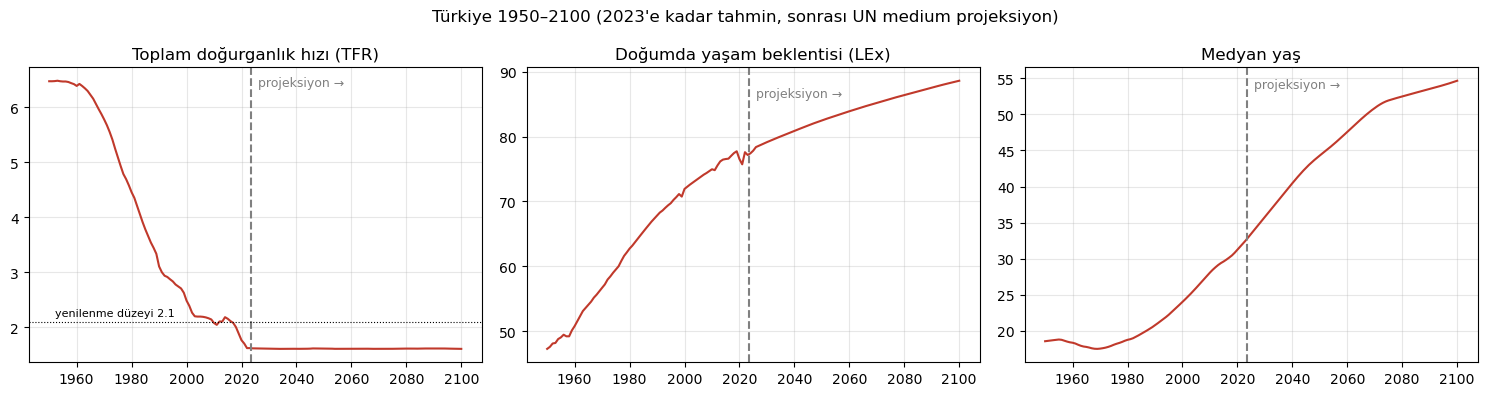

In [14]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col, title in zip(axes, ["TFR","LEx","MedianAgePop"],
                          ["Toplam doğurganlık hızı (TFR)", "Doğumda yaşam beklentisi (LEx)", "Medyan yaş"]):
    ax.plot(tr.index[tr.index<=2100], tr.loc[:2100, col], color="#c0392b")
    ax.axvline(2023.5, ls="--", color="gray")
    ax.text(2026, ax.get_ylim()[1]*0.95, "projeksiyon →", color="gray", fontsize=9)
    ax.set_title(title); ax.grid(alpha=.3)
axes[0].axhline(2.1, color="black", lw=.8, ls=":"); axes[0].text(1952, 2.2, "yenilenme düzeyi 2.1", fontsize=8)
fig.suptitle("Türkiye 1950–2100 (2023'e kadar tahmin, sonrası UN medium projeksiyon)")
plt.tight_layout(); plt.savefig("../outputs/01_turkiye_trend.png", dpi=150); plt.show()

In [15]:
tr_tr = m[m.Location == "Türkiye"].set_index("Time")
tr_tr.loc[2044:2050, ["TPopulation1July", "NatChange", "NetMigrations"]]


,TPopulation1July,NatChange,NetMigrations
Time,,,
2044,91353.308,125.907,-74.326
2045,91392.535,104.713,-77.842
2046,91418.744,83.081,-57.515
2047,91427.267,57.350,-65.876
2048,91404.165,28.386,-66.080
2049,91348.308,-1.917,-72.102
2050,91258.061,-32.413,-74.065


In [16]:
tr_tr["TPopulation1July"].idxmax()


np.int64(2047)

In [17]:
tr_tr["Toplam"] = tr_tr["NatChange"] + tr_tr["NetMigrations"]
tr_tr.loc[2044:2050, ["TPopulation1Jan", "NatChange", "NetMigrations", "Toplam", "PopChange"]]


,TPopulation1Jan,NatChange,NetMigrations,Toplam,PopChange
Time,,,,,
2044,91327.513,125.907,-74.326,51.581,51.591
2045,91379.104,104.713,-77.842,26.871,26.862
2046,91405.966,83.081,-57.515,25.566,25.557
2047,91431.523,57.350,-65.876,-8.526,-8.512
2048,91423.011,28.386,-66.080,-37.694,-37.692
2049,91385.319,-1.917,-72.102,-74.019,-74.021
2050,91311.298,-32.413,-74.065,-106.478,-106.474


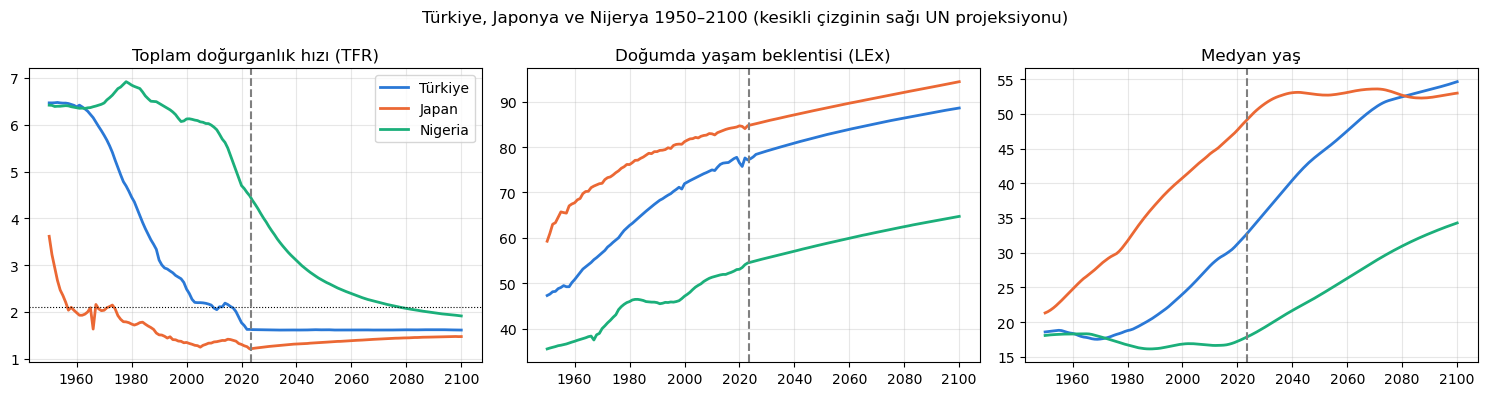

In [18]:
ulkeler = {"Türkiye": "#2a78d6", "Japan": "#eb6834", "Nigeria": "#1baf7a"}
gostergeler = [("TFR", "Toplam doğurganlık hızı (TFR)"),
               ("LEx", "Doğumda yaşam beklentisi (LEx)"),
               ("MedianAgePop", "Medyan yaş")]

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, (col, baslik) in zip(axes, gostergeler):
    for ulke, renk in ulkeler.items():
        d = m[(m.Location == ulke) & (m.Time <= 2100)]
        ax.plot(d.Time, d[col], color=renk, lw=2, label=ulke)
    ax.axvline(2023.5, ls="--", color="gray")
    ax.set_title(baslik); ax.grid(alpha=.3)
axes[0].axhline(2.1, color="black", lw=.8, ls=":")
axes[0].legend()
fig.suptitle("Türkiye, Japonya ve Nijerya 1950–2100 (kesikli çizginin sağı UN projeksiyonu)")
plt.tight_layout(); plt.savefig("../outputs/01_uc_ulke_karsilastirma.png", dpi=150); plt.show()


In [19]:
m.tail(3)	

,SortOrder,LocID,Notes,ISO3_code,ISO2_code,SDMX_code,LocTypeID,LocTypeName,ParentID,Location,VarID,Variant,Time,TPopulation1Jan,TPopulation1July,TPopulationMale1July,TPopulationFemale1July,PopDensity,PopSexRatio,MedianAgePop,NatChange,NatChangeRT,PopChange,PopGrowthRate,DoublingTime,Births,Births1519,CBR,TFR,NRR,MAC,SRB,Deaths,DeathsMale,DeathsFemale,CDR,LEx,LExMale,LExFemale,LE15,LE15Male,LE15Female,LE65,LE65Male,LE65Female,LE80,LE80Male,LE80Female,InfantDeaths,IMR,LBsurvivingAge1,Under5Deaths,Q5,Q0040,Q0040Male,Q0040Female,Q0060,Q0060Male,Q0060Female,Q1550,Q1550Male,Q1550Female,Q1560,Q1560Male,Q1560Female,NetMigrations,CNMR
84357,326.0,876,2,WLF,WF,876.0,4.0,Country/Area,957.0,Wallis and Futuna Islands,2,Medium,2099,7.002,6.958,3.527,3.431,49.7036,102.8126,54.3792,-0.078,-11.189,-0.087,-1.250,NaN,0.046,0.001,6.658,1.5266,0.7379,31.889,104.8,0.124,0.063,0.062,17.847,87.6210,87.1385,88.1159,73.1116,72.4487,73.7983,24.6268,23.9178,25.3599,12.8268,12.3475,13.2901,0.0,4.4823,0.046,0.0,5.2084,9.2641,6.4918,12.1705,31.6918,28.5670,34.9669,9.3653,7.9008,10.909,26.2007,25.0576,27.4040,-0.001,-0.109
84358,326.0,876,2,WLF,WF,876.0,4.0,Country/Area,957.0,Wallis and Futuna Islands,2,Medium,2100,6.915,6.878,3.487,3.390,49.1250,102.8462,54.5510,-0.078,-11.333,-0.075,-1.091,NaN,0.047,0.001,6.771,1.5271,0.7382,31.889,104.8,0.125,0.063,0.061,18.104,87.6952,87.1951,88.2125,73.1814,72.5035,73.8879,24.6841,23.9633,25.4336,12.8661,12.3781,13.3427,0.0,4.4391,0.047,0.0,5.1579,9.1714,6.4450,12.0295,31.3768,28.3501,34.5488,9.2681,7.8390,10.774,25.9376,24.8635,27.0678,-0.001,-0.168
84359,326.0,876,2,WLF,WF,876.0,4.0,Country/Area,957.0,Wallis and Futuna Islands,2,Medium,2101,6.840,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [20]:
m.sample(5, random_state=42)	

,SortOrder,LocID,Notes,ISO3_code,ISO2_code,SDMX_code,LocTypeID,LocTypeName,ParentID,Location,VarID,Variant,Time,TPopulation1Jan,TPopulation1July,TPopulationMale1July,TPopulationFemale1July,PopDensity,PopSexRatio,MedianAgePop,NatChange,NatChangeRT,PopChange,PopGrowthRate,DoublingTime,Births,Births1519,CBR,TFR,NRR,MAC,SRB,Deaths,DeathsMale,DeathsFemale,CDR,LEx,LExMale,LExFemale,LE15,LE15Male,LE15Female,LE65,LE65Male,LE65Female,LE80,LE80Male,LE80Female,InfantDeaths,IMR,LBsurvivingAge1,Under5Deaths,Q5,Q0040,Q0040Male,Q0040Female,Q0060,Q0060Male,Q0060Female,Q1550,Q1550Male,Q1550Female,Q1560,Q1560Male,Q1560Female,NetMigrations,CNMR
68918,225.0,688,24,SRB,RS,688.0,4.0,Country/Area,925.0,Serbia,2,Medium,2012,7348.795,7324.623,3488.864,3835.760,95.4522,90.9563,41.5594,-29.835,-4.073,-48.344,-0.660,NaN,70.637,3.931,9.644,1.4440,0.6894,28.489,107.0,100.472,54.301,46.171,13.717,75.0888,71.9312,78.2818,60.7094,57.5790,63.8673,15.5989,13.5874,17.4188,7.1190,5.8535,8.0536,0.441,6.2588,70.255,0.497,7.0631,26.0167,33.4410,18.5688,128.2883,168.9659,88.6548,45.3011,60.7310,30.2917,120.8787,161.2519,81.6593,-18.513,-2.528
30738,NaN,2035,NaN,NaN,NaN,NaN,NaN,NaN,NaN,UNICEF REGIONS,2,Medium,1984,4706640.925,4749360.794,2380668.368,2368692.426,36.6623,100.5056,21.8580,85460.338,17.994,85439.739,1.799,38.5296,133712.012,18774.936,28.154,3.5628,1.4789,27.532,105.9,48251.674,25591.434,22660.240,10.160,61.8090,59.3923,64.2752,55.4614,52.8976,58.0612,14.1554,12.6494,15.4195,6.5119,5.7070,7.0023,9964.223,74.8505,126494.663,14326.347,108.5918,183.6466,195.1071,171.7081,315.2849,353.4459,275.4663,117.5372,138.2027,95.9145,216.0437,257.4502,173.0348,-20.752,-0.004
21702,NaN,5522,NaN,NaN,NaN,NaN,NaN,NaN,NaN,"IPCC AR6: Australia, Japan, and New Zealand",2,Medium,2068,134399.022,134135.481,65237.984,68897.497,16.1143,94.6885,50.4746,-826.862,-6.164,-527.082,-0.393,NaN,1049.281,6.605,7.823,1.4866,0.7227,32.883,105.2,1876.143,921.597,954.546,13.987,90.2519,87.6061,92.8964,75.3687,72.7396,77.9940,26.7480,24.5434,28.8718,13.5677,11.9147,15.0006,0.850,0.8097,1048.557,1.110,1.0551,5.9631,8.1245,3.7501,24.9770,33.9725,15.7647,10.2772,14.0806,6.4064,23.6763,32.4501,14.7013,299.800,2.235
71361,241.0,660,19,AIA,AI,660.0,4.0,Country/Area,915.0,Anguilla,2,Medium,2023,14.297,14.410,7.003,7.407,163.7500,94.5457,38.0127,0.034,2.343,0.226,1.568,44.2058,0.130,0.017,9.028,1.3644,0.6650,28.246,103.6,0.096,0.055,0.041,6.685,79.3115,76.0259,82.6639,64.8458,61.6951,68.0443,18.3278,16.0859,20.4649,8.3036,7.0408,9.1828,0.001,4.8579,0.129,0.001,5.6794,20.2583,28.3226,12.0963,81.6839,110.1326,53.8103,30.3092,41.8290,19.1656,75.3271,102.0763,49.3401,0.200,13.879
82727,316.0,585,NaN,PLW,PW,585.0,4.0,Country/Area,954.0,Palau,2,Medium,1989,14.801,14.945,8.038,6.907,32.4891,116.3747,23.8706,0.185,12.373,0.288,1.927,35.9703,0.332,0.038,22.218,2.9166,1.3184,28.859,107.7,0.147,0.094,0.053,9.845,62.7767,58.0673,69.5665,50.6403,46.0193,57.3477,12.3304,10.4377,14.3252,5.7086,4.9620,6.1177,0.010,29.2235,0.324,0.012,36.0112,138.0204,177.9846,84.6636,347.9186,447.1266,207.7870,180.6894,244.5830,90.8588,316.9883,417.7248,175.0790,0.113,7.561


In [21]:
m[m.Location=="Türkiye"].head(3)	

,SortOrder,LocID,Notes,ISO3_code,ISO2_code,SDMX_code,LocTypeID,LocTypeName,ParentID,Location,VarID,Variant,Time,TPopulation1Jan,TPopulation1July,TPopulationMale1July,TPopulationFemale1July,PopDensity,PopSexRatio,MedianAgePop,NatChange,NatChangeRT,PopChange,PopGrowthRate,DoublingTime,Births,Births1519,CBR,TFR,NRR,MAC,SRB,Deaths,DeathsMale,DeathsFemale,CDR,LEx,LExMale,LExFemale,LE15,LE15Male,LE15Female,LE65,LE65Male,LE65Female,LE80,LE80Male,LE80Female,InfantDeaths,IMR,LBsurvivingAge1,Under5Deaths,Q5,Q0040,Q0040Male,Q0040Female,Q0060,Q0060Male,Q0060Female,Q1550,Q1550Male,Q1550Female,Q1560,Q1560Male,Q1560Female,NetMigrations,CNMR
62016,180.0,792,NaN,TUR,TR,792.0,4.0,Country/Area,922.0,Türkiye,2,Medium,1950,20715.337,21021.140,10542.754,10478.386,27.3142,100.6143,18.5708,559.996,26.640,611.605,2.910,23.8195,982.482,160.290,46.738,6.4680,2.1117,28.111,104.6,422.486,226.753,195.733,20.098,47.2916,44.2318,50.4128,54.3500,50.9605,57.6851,14.0218,12.4531,15.2060,6.3329,5.4580,6.9879,187.368,193.3691,849.333,294.599,310.1503,376.5711,398.1828,353.6961,486.1454,538.1750,432.6742,132.4411,162.5510,100.6482,239.4672,304.1745,175.1949,51.619,2.456
62017,180.0,792,NaN,TUR,TR,792.0,4.0,Country/Area,922.0,Türkiye,2,Medium,1951,21326.942,21643.880,10881.230,10762.650,28.1234,101.1018,18.6231,576.662,26.643,633.877,2.929,23.6650,1013.349,165.893,46.819,6.4677,2.1243,28.088,104.6,436.687,234.297,202.390,20.176,47.6043,44.6083,50.6697,54.3482,51.0330,57.6270,14.0030,12.4583,15.1618,6.3181,5.4588,6.9402,195.726,191.1380,877.602,304.355,304.9576,372.0425,392.9651,349.8825,482.5242,533.3341,429.8071,131.9497,161.2024,100.9183,239.1734,302.1174,175.8506,57.204,2.643
62018,180.0,792,NaN,TUR,TR,792.0,4.0,Country/Area,922.0,Türkiye,2,Medium,1952,21960.819,22290.092,11233.002,11057.090,28.9631,101.5909,18.6736,599.540,26.897,658.546,2.955,23.4568,1045.183,170.327,46.890,6.4705,2.1528,28.064,104.6,445.643,239.278,206.365,19.993,48.1208,45.1361,51.1955,54.2514,50.9942,57.5008,13.9328,12.4056,15.0805,6.2763,5.4303,6.8774,199.528,188.8983,906.812,311.335,299.9326,363.8481,384.7289,341.7046,476.6498,527.2159,423.6231,132.3708,161.0807,101.7876,240.4308,302.1683,177.5319,59.001,2.647


In [22]:
m.head(3).T	

,0,1,2
SortOrder,NaN,NaN,NaN
LocID,5507,5507,5507
Notes,NaN,NaN,NaN
ISO3_code,NaN,NaN,NaN
ISO2_code,NaN,NaN,NaN
...,...,...,...
Q1560,443.3215,436.9979,429.8298
Q1560Male,457.3384,451.4368,444.5151
Q1560Female,427.3167,420.7398,413.5565
NetMigrations,201.196,195.07,182.671


## Faz 1 Özeti (bulgular)
- Veri **panel** yapıda: Location × Time.
- 553 Location'ın yalnızca **237'si ülke** (`LocTypeName == "Country/Area"`); geri kalanı toplam/grup → toplarsan çifte sayım olur.
- 54 gösterge Medium'da, 5 gösterge Supplement'ta.
- 2101'de neredeyse her şey boş → 1950–2100 kullanacağız.
- Geri kalan tek eksik `DoublingTime` (tanım gereği; büyüme < %0.5 iken boş) → değişkeni çıkaracağız.
- 2023'e kadar *estimate*, 2024+ *projection*.

**Sonraki adım (Faz 2):** temiz ülke veri seti oluşturmak.